# Part 3 — Gradual semantics

## Question 2: visualising the acceptability degree space

In this question, we try to visualise the **acceptability degree space** of the weighted h-categorizer: the set of all the degrees the arguments of a graph can get, when the weights can be anything between 0 and 1. We want to see which degrees are possible, which ones are impossible, and how this space changes with the attacks and the number of arguments.

How we do it:
- we take a graph $(A, R)$ and give it 100,000 random weight vectors;
- for each one, we compute the degrees with the h-categorizer from Question 1, so each weight vector gives one point (one degree per argument);
- we draw the **convex hull** around these points, to see which degrees are possible;
- we add a **heat-map**, to see where the points are dense, i.e. which degrees are frequent.

Then we answer these questions: is the heat-map resilient to re-sampling ? What happens when we change the graph and the number of arguments? We end with our analysis.

To keep the notebook easy to read, we put the code we reuse in two files:
- `q2_tools.py`: our functions for this question (sampling the weights and computing the degrees, building and drawing the hull, the heat-map, and comparing heat-maps);
- `graphs.py`: the argumentation frameworks we test (with 2, 3 and 4 arguments).

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from graphs import TWO_ARGUMENT_GRAPHS, THREE_ARGUMENT_GRAPHS, FOUR_ARGUMENT_GRAPH
from itertools import combinations
from math import comb
import time
from q2_tools import (degrees_for_random_weights, show_samples, compute_hull,
                      draw_hull_2d, draw_heatmap_2d, density_grid, heatmap_difference,
                      draw_hull_3d, draw_heatmap_3d, real_space_volume, draw_correlation_matrix)

## Step 1: Take as input an argumentation framework (A, R)

We start with the simplest example: two arguments, b attacks a, no weights.

In [2]:
arguments = ["a", "b"]
attacks = [("b", "a")]

## Step 2: Sample 100,000 random vectors $w_i$ and compute the vectors $x_i$

We give the graph 100,000 random weight vectors, so we get 100,000 weighted graphs $(A, R, w_i)$, and we run the weighted h-categorizer from Question 1 on each of them.
- `W`: one row = the weights $w_i = [w(a), w(b)]$ of graph $i$
- `X`: one row = the final degrees $x_i = [Deg(a), Deg(b)]$ of graph $i$

In [3]:
W, X = degrees_for_random_weights(arguments, attacks, n_samples=100_000, seed=0)
print(W.shape, X.shape)

(100000, 2) (100000, 2)


**What we get.** The first 10 samples:

In [4]:
show_samples(arguments, W, X, n=10)

,w(a),w(b),Deg(a),Deg(b)
0,0.637,0.270,0.502,0.270
1,0.041,0.017,0.040,0.017
2,0.813,0.913,0.425,0.913
3,0.607,0.729,0.351,0.729
4,0.544,0.935,0.281,0.935
5,0.816,0.003,0.814,0.003
6,0.857,0.034,0.830,0.034
7,0.730,0.176,0.621,0.176
8,0.863,0.541,0.560,0.541
9,0.300,0.423,0.211,0.423


- b is not attacked, so $Deg(b) = w(b)$ in every row.
- a is attacked by b, so $Deg(a) = w(a) / (1 + w(b))$. First row: $0.637 / 1.27 = 0.502$.
- When b is strong (row 2, $w(b) = 0.913$), a drops a lot even with a high weight.

Each row of X is a point (degree of a, degree of b). We now look at the 100,000 points together.

## Step 3: Construct and display the convex hull

hull area: 0.748


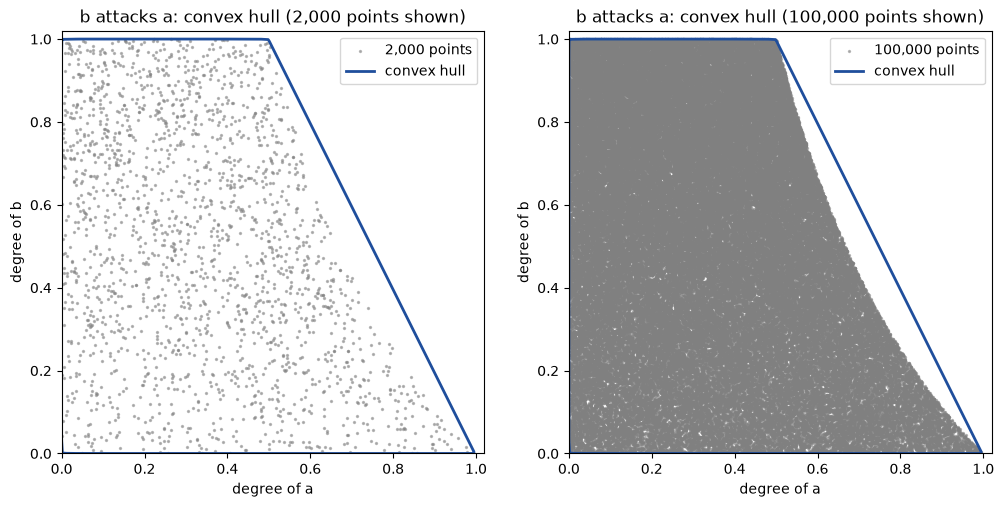

In [5]:
hull = compute_hull(X)
print("hull area:", round(hull.volume, 3))

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
# left: 2,000 points (we can see the points one by one)
# right: all 100,000 points (we can see the exact border of the cloud)
for ax, n in zip(axs, [2_000, 100_000]):
    ax.scatter(X[:n, 0], X[:n, 1], s=2, color="grey", alpha=0.5, label=f"{n:,} points")
    draw_hull_2d(ax, X, hull)
    ax.set_title(f"b attacks a: convex hull ({n:,} points shown)")
    ax.legend(loc="upper right")
plt.show()

The hull is always computed on the 100,000 points. On the left we only show 2,000 of them to see the points one by one; on the right we show all of them: the cloud becomes a solid shape and its curved border is easy to see.

The top-right corner is outside the hull: a and b can never both be strong. When b is close to 1, a cannot go above 0.5. On the right we also see a white strip between the curved border of the cloud and the straight line of the hull.

## Step 4: Apply a heat-map on the convex hull

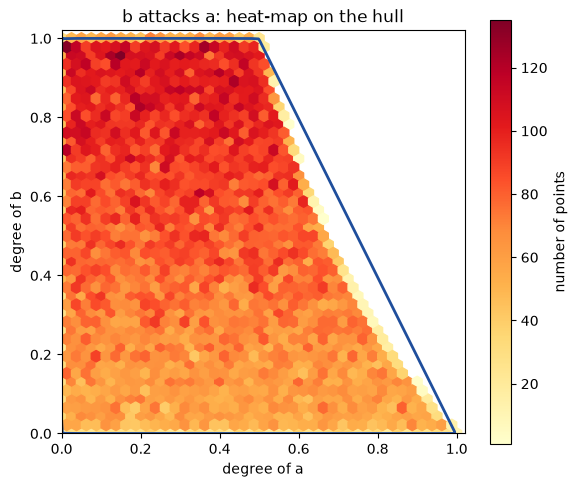

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
hb = draw_heatmap_2d(ax, X)
draw_hull_2d(ax, X, hull)
fig.colorbar(hb, ax=ax, label="number of points")
ax.set_title("b attacks a: heat-map on the hull")
plt.show()

- The heat-map is not uniform even if the weights are: darker at the top left. When b is strong, all the degrees of a are squeezed between 0 and 0.5, so the points pile up there.
- The right border of the cloud is a curve ($Deg(a) = 1/(1+Deg(b))$), but the hull is made of straight lines, so there is a white strip inside the hull where no point can be. We will measure it later.

## Step 5: Is this heat-map resilient to re-sampling?

Our heat-map comes from random weights. If we draw new weights (another seed), do we get the same picture? If not, what we see is just noise.

We keep the same graph (b attacks a) and only change the seed. First, by eye:

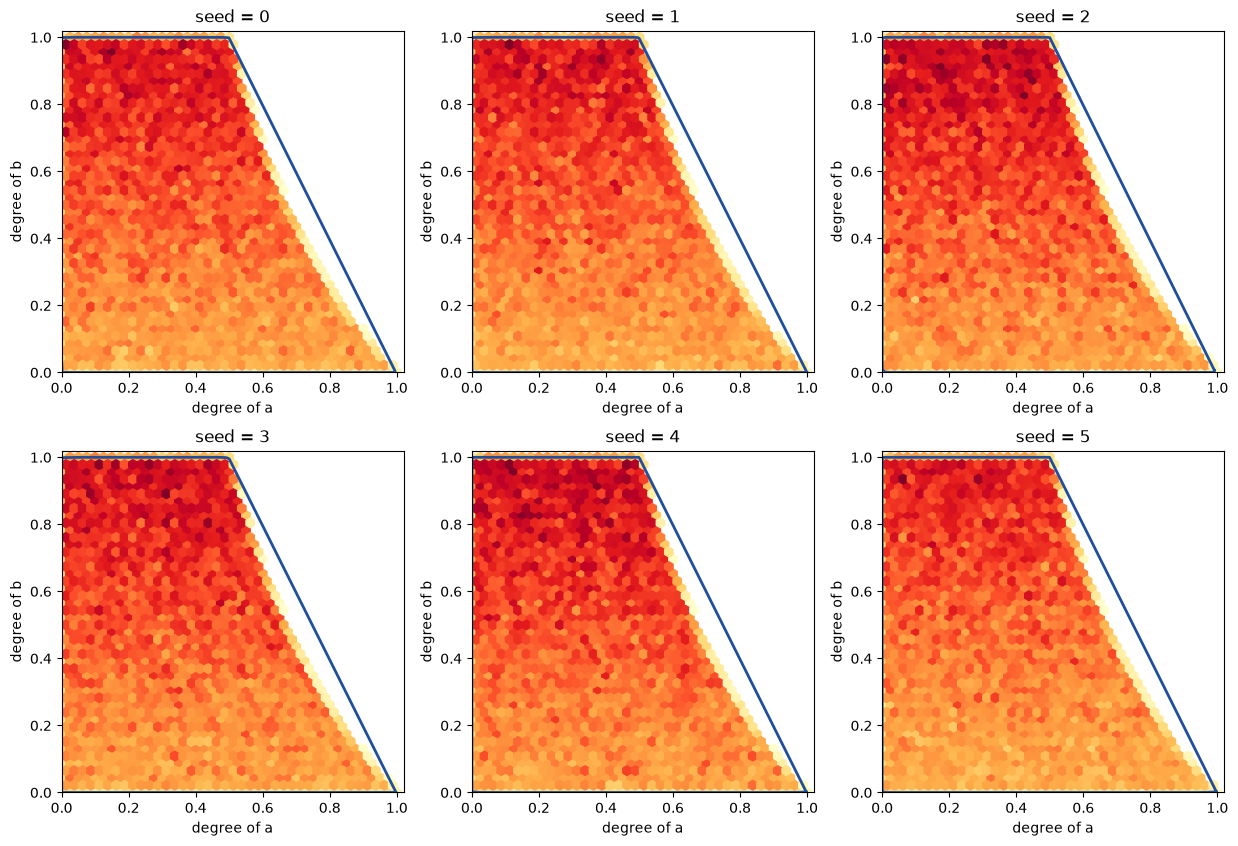

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, seed in zip(axs.flat, [0, 1, 2, 3, 4, 5]):
    W, X = degrees_for_random_weights(arguments, attacks, seed=seed)
    draw_heatmap_2d(ax, X)
    draw_hull_2d(ax, X, compute_hull(X))
    ax.set_title(f"seed = {seed}")
plt.show()

By eye, the six heat-maps look the same, so the heat-map seems resilient to re-sampling. To check this further with a number, we use two functions:
- `density_grid` cuts the square into 40 x 40 cells and gives the share of points in each cell. It is the heat-map of each seed written as numbers, so we can study where the points are concentrated.
- `heatmap_difference` compares two of these grids: it gives the share of points that are not in the same cell (0 = identical, 1 = completely different).

We take seed 0 as the reference and compare it with the five other seeds.

In [8]:
# reference heat-map: seed 0
reference = density_grid(degrees_for_random_weights(arguments, attacks, seed=0)[1])

rows = []
# compare the 5 other seeds with the reference
for seed in [1, 2, 3, 4, 5]:
    W, X = degrees_for_random_weights(arguments, attacks, seed=seed)
    rows.append({"seed": seed,
                 "difference with seed 0": heatmap_difference(reference, density_grid(X)),
                 "hull area": compute_hull(X).volume})
pd.DataFrame(rows).round(4).set_index("seed")

,difference with seed 0,hull area
seed,,
1,0.0585,0.7483
2,0.0598,0.7466
3,0.0596,0.7476
4,0.0584,0.7483
5,0.0612,0.7485


- Compared with seed 0, only about 6% of the points land in a different cell: the heat-map is stable.
- The hull area barely changes (0.7466 to 0.7485).

Is 100,000 samples enough? For each number of samples, we draw 6 seeds and compare every pair of heat-maps (15 pairs):

In [9]:
rows = []

# we try with more and more samples
for n in [1_000, 10_000, 100_000, 1_000_000]:

    # for each of the 6 seeds: random weights -> degrees -> heat-map as numbers (40 x 40 grid)
    grids = []
    for seed in range(6):
        W, X = degrees_for_random_weights(arguments, attacks, n_samples=n, seed=seed)
        grids.append(density_grid(X))

    # compare every pair of seeds: (0,1), (0,2), ..., (4,5) -> 15 pairs
    diffs = []
    for i in range(6):
        for j in range(i + 1, 6):
            diffs.append(heatmap_difference(grids[i], grids[j]))

    # keep the mean, the smallest and the largest difference for this number of samples
    rows.append({"samples": n,
                 "mean difference": np.mean(diffs),
                 "min": np.min(diffs),
                 "max": np.max(diffs)})

# one row per number of samples
pd.DataFrame(rows).round(4).set_index("samples")

,mean difference,min,max
samples,,,
1000,0.5345,0.5110,0.5490
10000,0.1887,0.1818,0.1962
100000,0.0600,0.0584,0.0634
1000000,0.0191,0.0182,0.0198


- With 1,000 samples, two draws give very different heat-maps: about 53% of the points land in a different cell. The heat-map is not reliable.
- The difference goes down each time we add samples: 53% → 19% → 6% → 2% (about ÷3 each time we multiply by 10).
- The min and max are always close to the mean (15 pairs of seeds), so this is not luck: the trend is the same for every pair.
- With 100,000 samples the difference is about 6%: the shape and the dense areas of the heat-map are reliable.

**Conclusion:** the more samples we draw, the more stable the heat-map is. The small differences between two draws only come from randomness, and they disappear as the number of samples grows. With 100,000 samples, the heat-map is resilient to re-sampling.

## Step 6: Vary the argumentation frameworks

With b attacks a, we saw some things. Now we change the graph and ask: does anything change?

1. Does every attack cut away the region where both arguments are strong?
2. Do the points always pile up where an attacked argument is squeezed?
3. Does the hull always cover empty areas?
4. Is the heat-map still stable with 100,000 samples?

We keep 2 arguments and only change the attacks:
- **no attack**: our reference, nothing limits the degrees
- **b attacks a**: our first example
- **a and b attack each other**: a cycle
- **a attacks itself**: b is alone

In [10]:
TWO_ARGUMENT_GRAPHS

{'no attack': [],
 'b attacks a': [('b', 'a')],
 'a and b attack each other': [('a', 'b'), ('b', 'a')],
 'a attacks itself': [('a', 'a')]}

### Questions 1 and 2: the shape and the heat-map

For each graph we do the same steps as before: random weights → degrees → convex hull → heat-map.

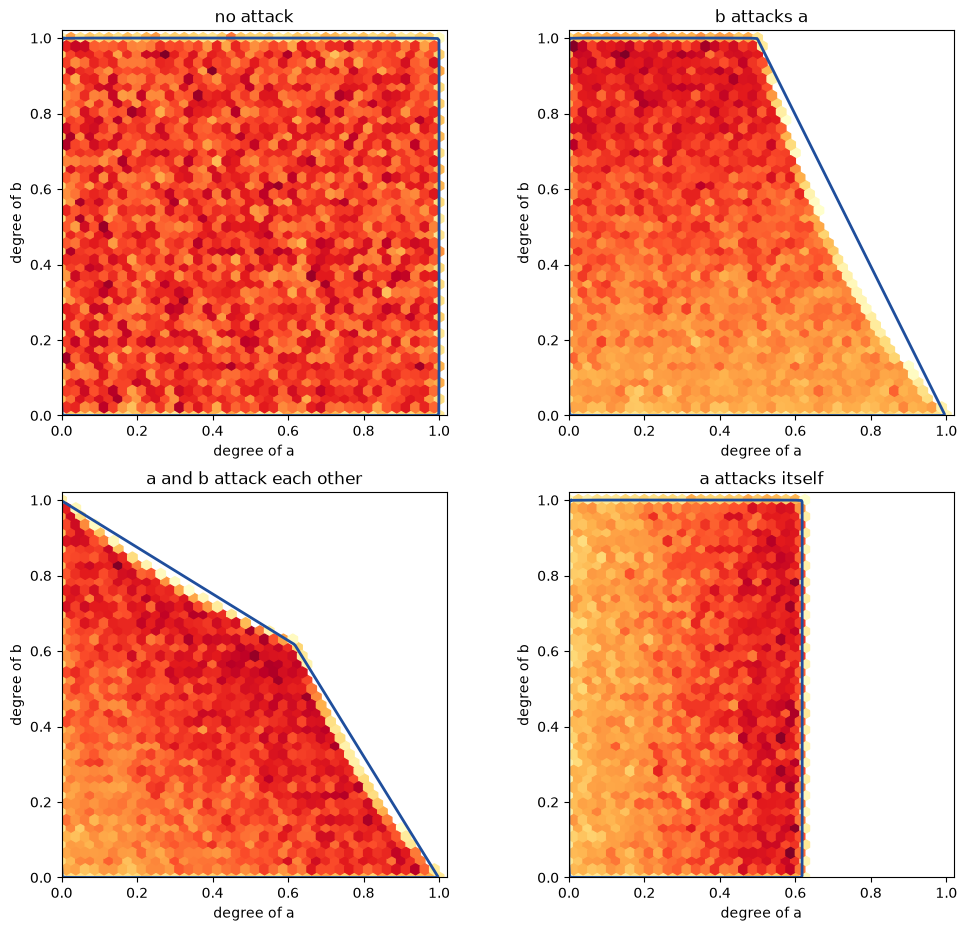

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(12, 11))

# one plot per graph
for ax, (name, graph_attacks) in zip(axs.flat, TWO_ARGUMENT_GRAPHS.items()):
    # random weights -> degrees
    W, X = degrees_for_random_weights(arguments, graph_attacks, seed=0)
    # heat-map + convex hull
    draw_heatmap_2d(ax, X)
    draw_hull_2d(ax, X, compute_hull(X))
    ax.set_title(name)
plt.show()

The plots give us a first idea of the space, but it is hard to compare the graphs only by eye. To compare them more precisely, we describe each space with three metrics:
- **hull area**: the size of the space (1 = the whole square, every combination of degrees is possible).
- **all > 0.5 (%)**: how often all the arguments are strong at the same time (0.5 = the middle of the scale). Without any attack it would be $0.5^2 = 25\%$, so we can see how much each attack cuts this region. If it is 0%, this region is outside the space.
- **mean Deg**: where the degree of an argument usually ends up when the weights are random. It does not describe the space itself but where the points fall inside it, like the heat-map in one number.

In [12]:
rows = []
for name, graph_attacks in TWO_ARGUMENT_GRAPHS.items():
    W, X = degrees_for_random_weights(arguments, graph_attacks, seed=0)
    rows.append({"graph": name,
                 "hull area": compute_hull(X).volume,
                 "mean Deg(a)": X[:, 0].mean(),
                 "mean Deg(b)": X[:, 1].mean(),
                 "all > 0.5 (%)": 100 * np.mean((X > 0.5).all(axis=1))})
pd.DataFrame(rows).round(3).set_index("graph")

,hull area,mean Deg(a),mean Deg(b),all > 0.5 (%)
graph,,,,
no attack,1.000,0.499,0.500,24.870
b attacks a,0.748,0.346,0.500,6.170
a and b attack each other,0.616,0.380,0.381,4.144
a attacks itself,0.618,0.348,0.500,12.430


Based on the metrics we calculated:

- **No attack**: the degrees are the weights, the whole square is filled evenly (area 1). Nothing is cut and the heat-map is uniform: this confirms that the cut corner and the dark areas come from the attacks.
- **b attacks a**: at least a quarter of the square becomes impossible (hull area 0.75, and the hull is a bit too big), and both arguments are above 0.5 in only 6% of the samples, against 25% without attack.
- **a and b attack each other**: the corner is cut on both sides (area 0.62), both arguments lose (average 0.38). When both weights are 1 they meet at 0.618, the value of the cycle from Question 1. The points pile up along the outer border.
- **a attacks itself**: a never goes above 0.618, whatever its weight, so the space is a rectangle (area 0.62). b is alone and covers the whole axis. The points pile up on the right, just below 0.618.

So the answer to questions 1 and 2 is yes: every attack makes the space smaller and cuts away the region where both arguments are strong, and the points always pile up where an attacked argument is squeezed.

### Question 3: does the hull still cover empty areas?

We look again at the four plots above:
- For **b attacks a** and **a and b attack each other**, the border of the cloud is curved, so the hull (straight lines) covers a white strip where there is no point.
- For **no attack** and **a attacks itself**, the space is a square or a rectangle, so the hull fits the cloud exactly.

So the answer to question 3 is: only when the border of the space is curved. The hull is a good approximation only when the space itself has straight borders.

### Question 4: is the heat-map still stable?

Same test as in Step 5 (6 seeds, 15 pairs), for each graph.

In [13]:
rows = []
for name, graph_attacks in TWO_ARGUMENT_GRAPHS.items():
    # one heat-map (as numbers) per seed
    grids = []
    for seed in range(6):
        W, X = degrees_for_random_weights(arguments, graph_attacks, seed=seed)
        grids.append(density_grid(X))
    # compare every pair of seeds (15 pairs)
    diffs = []
    for i in range(6):
        for j in range(i + 1, 6):
            diffs.append(heatmap_difference(grids[i], grids[j]))
    rows.append({"graph": name,
                 "mean difference": np.mean(diffs),
                 "min": np.min(diffs),
                 "max": np.max(diffs)})
pd.DataFrame(rows).round(4).set_index("graph")

,mean difference,min,max
graph,,,
no attack,0.0713,0.0691,0.0741
b attacks a,0.0600,0.0584,0.0634
a and b attack each other,0.0546,0.0537,0.0560
a attacks itself,0.0567,0.0553,0.0588


- The heat-map is stable for all four graphs (about 5.5 to 7% difference between two draws), and the min and max are close to the mean.
- No attack is a bit higher (7%): its points are spread over the whole square, so each cell gets fewer points and is more affected by randomness.

### What still stands?

1. Does every attack cut the corner where both arguments are strong? -> yes, for every attack.
2. Do the points pile up where an attacked argument is squeezed? -> yes, for every attack (uniform without attack).
3. Does the hull cover areas where there is no point? -> only when the border of the space is curved.
4. Is the heat-map stable with 100,000 samples? -> yes, for every graph.

## Step 7: Vary the number of arguments

### 3 arguments

We used the method on graphs with 2 arguments. Let's try with 3 arguments: does what we noticed still stand, and what changes?

Each point now has 3 coordinates (degree of a, b and c), so the space is a volume and we plot it in 3D. We pick 3 graphs, each one adds something we could not see with 2 arguments:
- **chain c → b → a**: c attacks the attacker of a, so c *defends* a
- **two attackers b → a, c → a**: a is attacked twice
- **3-cycle a → b → c → a**: a cycle with 3 arguments

In [14]:
arguments_3 = ["a", "b", "c"]
THREE_ARGUMENT_GRAPHS

{'chain: c -> b -> a': [('c', 'b'), ('b', 'a')],
 'two attackers: b -> a, c -> a': [('b', 'a'), ('c', 'a')],
 '3-cycle: a -> b -> c -> a': [('a', 'b'), ('b', 'c'), ('c', 'a')]}

First, a look at the chain: the first 10 samples.

In [15]:
W, X = degrees_for_random_weights(arguments_3, THREE_ARGUMENT_GRAPHS["chain: c -> b -> a"], seed=0)
show_samples(arguments_3, W, X, n=10)

,w(a),w(b),w(c),Deg(a),Deg(b),Deg(c)
0,0.637,0.270,0.041,0.506,0.259,0.041
1,0.017,0.813,0.913,0.012,0.425,0.913
2,0.607,0.729,0.544,0.412,0.473,0.544
3,0.935,0.816,0.003,0.516,0.814,0.003
4,0.857,0.034,0.730,0.841,0.019,0.730
5,0.176,0.863,0.541,0.113,0.560,0.541
6,0.300,0.423,0.028,0.212,0.411,0.028
7,0.124,0.671,0.647,0.088,0.407,0.647
8,0.615,0.384,0.997,0.516,0.192,0.997
9,0.981,0.686,0.650,0.693,0.415,0.650


- c is not attacked, so its degree is its weight.
- b is attacked by c, and a is attacked by b, like before.
- When c is strong, b is weakened, so a gets back more of its weight (row 8: c = 0.997, b drops to 0.192, a keeps 0.516 out of 0.615).

We now do the same steps as with 2 arguments, in 3D. First the convex hull (light blue surface), with all 100,000 points.

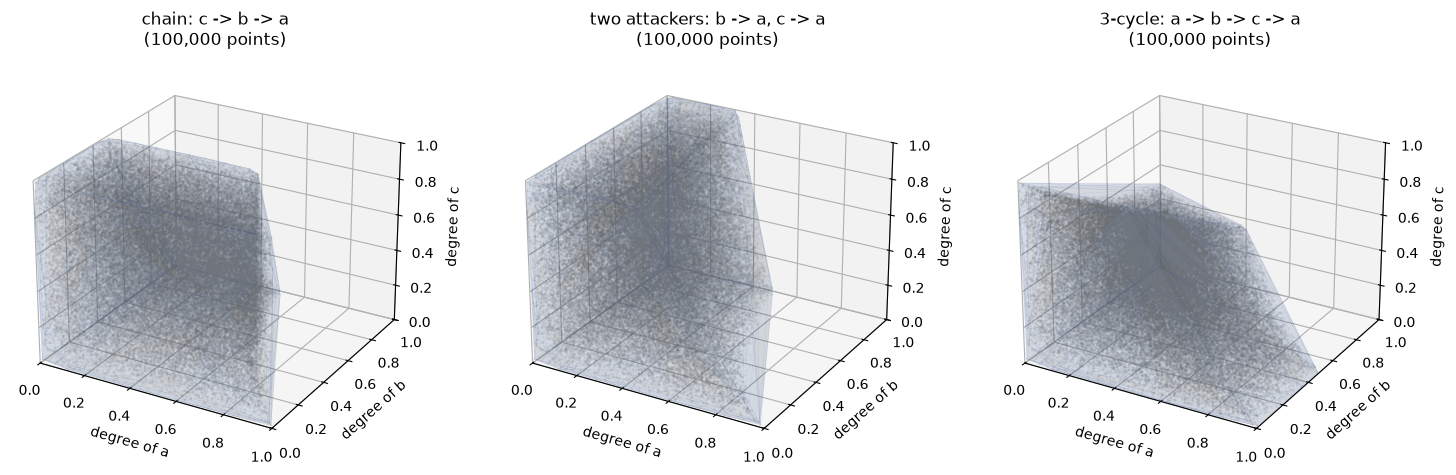

In [16]:
fig = plt.figure(figsize=(18, 6))

# one 3D plot per graph, with all 100,000 points
for k, (name, graph_attacks) in enumerate(THREE_ARGUMENT_GRAPHS.items()):
    # random weights -> degrees
    W, X = degrees_for_random_weights(arguments_3, graph_attacks, seed=0)
    # points + convex hull
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=1, color="grey", alpha=0.3)
    draw_hull_3d(ax, X, compute_hull(X))
    ax.set_title(f"{name}\n(100,000 points)")
    ax.view_init(25, -60)

plt.show()

- In 3D, the hull looks like a cube with some parts cut off by the attacks.
- c is not attacked in the chain and with two attackers: it keeps its weight, so its degree still goes all the way up to 1 (the top of the cube is reached).
- In the chain, a is defended by c (c weakens b), so a seems to keep higher degrees. With two attackers, a is attacked by both b and c, so it goes even lower.
- In the 3-cycle, every argument is attacked, so the space is much smaller.
- Like in 2D, the hull is made of flat faces while the real border of the cloud is curved, so the hull is a bit bigger than the real space.

This confirms what we saw with 2 arguments: the attacks limit the possible degrees, and the more an argument is attacked, the more it is limited.

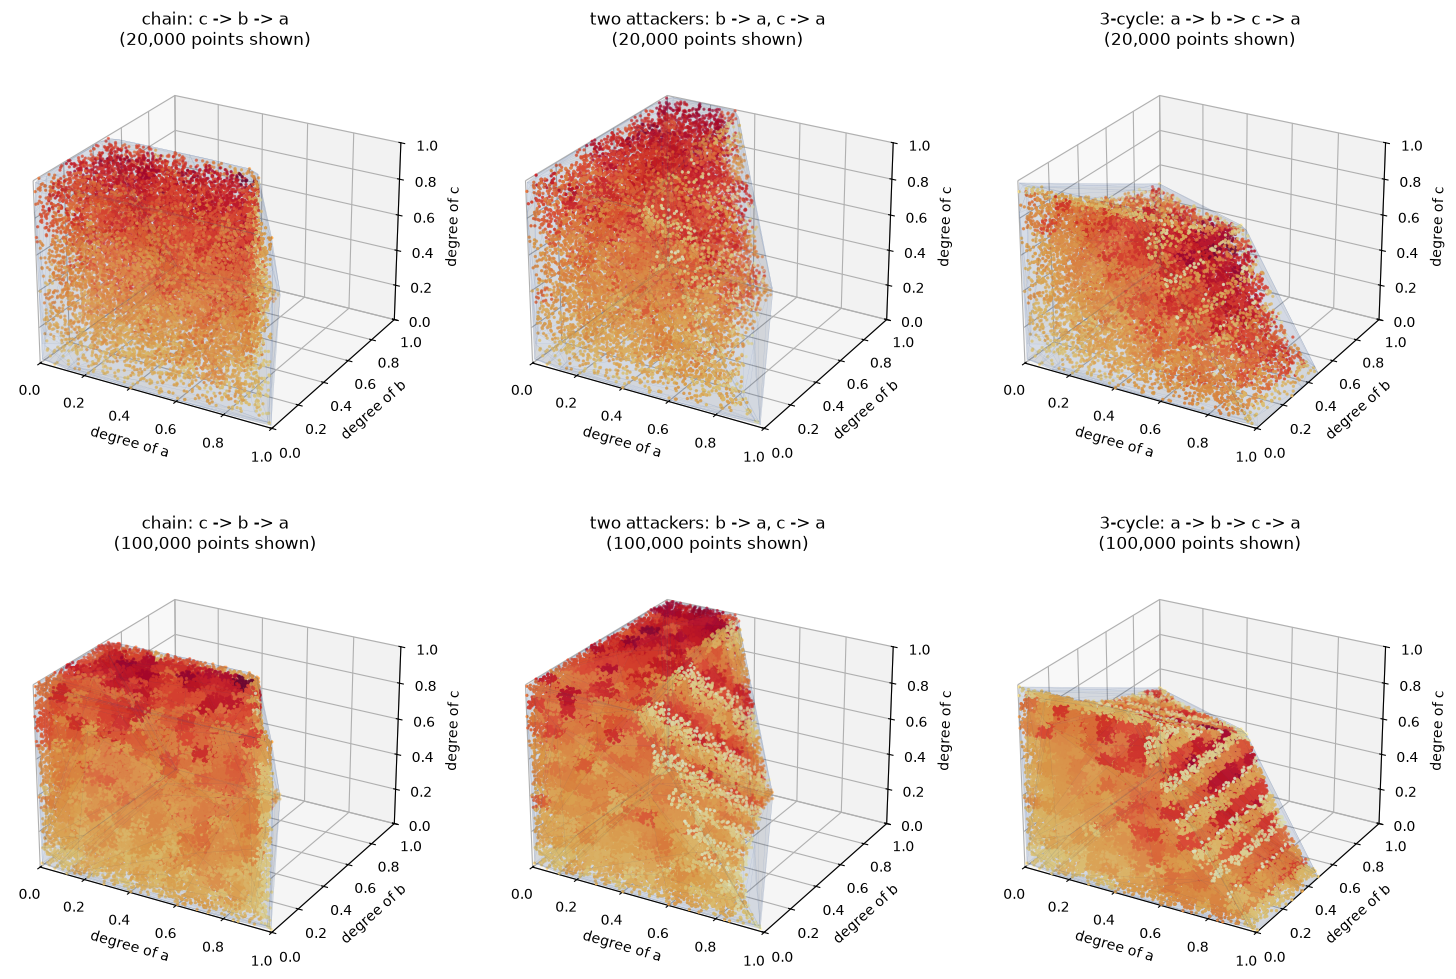

In [17]:
fig = plt.figure(figsize=(18, 12))

# top row: 20,000 points, bottom row: 100,000 points
for row, n in enumerate([20_000, 100_000]):
    for k, (name, graph_attacks) in enumerate(THREE_ARGUMENT_GRAPHS.items()):
        # random weights -> degrees
        W, X = degrees_for_random_weights(arguments_3, graph_attacks, seed=0)
        # 3D heat-map + convex hull
        ax = fig.add_subplot(2, 3, row * 3 + k + 1, projection="3d")
        draw_heatmap_3d(ax, X, n_show=n)
        draw_hull_3d(ax, X, compute_hull(X))
        ax.set_title(f"{name}\n({n:,} points shown)")
        ax.view_init(25, -60)
plt.show()

- With 20,000 points we can see inside the cloud: the points pile up at the top for the chain and the two attackers (c is strong, so the argument it attacks is squeezed), and along the cut side for the 3-cycle.
- With 100,000 points the cloud becomes a solid block and we only see its outside.

Like in 2D, the attacks do not only limit the possible degrees, they also change how often each degree appears: the points pile up where an attacked argument is squeezed.

The plots give us a first idea of the space, but we can only read them from one angle. To compare the graphs more precisely, we describe each space with three metrics:
- **hull volume**: how big the space is (1 = the whole cube).
- **all > 0.5 (%)**: how often all the arguments are strong at the same time.
- **mean Deg**: the average degree of each argument over all the samples. It tells us where the degree of an argument usually ends up when the weights are random: a low mean means the argument is usually weak in this graph.

In [18]:
rows = []
for name, graph_attacks in THREE_ARGUMENT_GRAPHS.items():
    W, X = degrees_for_random_weights(arguments_3, graph_attacks, seed=0)
    rows.append({"graph": name,
                 "hull volume": compute_hull(X).volume,
                 "mean Deg(a)": X[:, 0].mean(),
                 "mean Deg(b)": X[:, 1].mean(),
                 "mean Deg(c)": X[:, 2].mean(),
                 "all > 0.5 (%)": 100 * np.mean((X > 0.5).all(axis=1))})
pd.DataFrame(rows).round(3).set_index("graph")

,hull volume,mean Deg(a),mean Deg(b),mean Deg(c),all > 0.5 (%)
graph,,,,,
chain: c -> b -> a,0.589,0.382,0.345,0.500,1.363
"two attackers: b -> a, c -> a",0.600,0.262,0.498,0.500,0.000
3-cycle: a -> b -> c -> a,0.472,0.373,0.371,0.373,1.024


Based on the metrics we calculated:

- **The size of the space.** In the plots, part of the cube is cut for every graph. The numbers say by how much: the space goes from the whole cube (volume 1) to about 0.59 for the chain and the two attackers, and 0.47 for the 3-cycle, where every argument is attacked and the cube is cut on all sides.
- **What is impossible.** The cut part is the region where the arguments are strong together. Without attacks, all three degrees are above 0.5 in 12.5% of the samples; with attacks only 0 to 1.4%. With two attackers it never happens: a can only be above 0.5 if $Deg(b) + Deg(c) < 1$.
- **Where the points fall inside the space.** In the chain, c weakens b, so a gets back some room: its average degree (0.38) is higher than with one attacker (0.35). With two attackers, a drops to 0.26: the two attacks add up. In the 3-cycle, the three arguments have the same role and the same average (0.37).
- **Our reference.** c is not attacked in the chain and the two attackers, so its mean is 0.5: its degree is its weight, and the weights are random between 0 and 1. Every attacked argument is below this 0.5.

So the visualisation and the numbers tell the same story as with 2 arguments: the attacks decide which degrees are possible, and the weights only choose a point inside this space.

Is the heat-map still stable with 3 arguments? Same test as before (6 seeds, 15 pairs). We cut the cube into 12 x 12 x 12 = 1,728 small cubes: about the same number of cells as the 40 x 40 = 1,600 grid in 2D, so each cell gets about the same number of points and we can compare with 2 arguments.

In [19]:
rows = []
for name, graph_attacks in THREE_ARGUMENT_GRAPHS.items():
    # one heat-map (as numbers) per seed
    grids = []
    for seed in range(6):
        W, X = degrees_for_random_weights(arguments_3, graph_attacks, seed=seed)
        grids.append(density_grid(X, bins=12))
    # compare every pair of seeds (15 pairs)
    diffs = []
    for i in range(6):
        for j in range(i + 1, 6):
            diffs.append(heatmap_difference(grids[i], grids[j]))
    rows.append({"graph": name,
                 "mean difference": np.mean(diffs),
                 "min": np.min(diffs),
                 "max": np.max(diffs)})
pd.DataFrame(rows).round(4).set_index("graph")

,mean difference,min,max
graph,,,
chain: c -> b -> a,0.0553,0.0535,0.0570
"two attackers: b -> a, c -> a",0.0551,0.0533,0.0571
3-cycle: a -> b -> c -> a,0.0504,0.0488,0.0523


- The heat-map is still stable: between two draws, only about 5% of the points land in a different small cube, and the min and max are close to the mean.
- This is the same as with 2 arguments: adding a third argument does not make the heat-map less stable.
- The 3-cycle is the most stable: its space is the smallest, so the points are more packed in each small cube.

### What still stands?
1. does every attack cut the region where all arguments are strong? -> yes, for every attack, and the space gets smaller
2. do the points pile up where an argument is squeezed? -> yes, for every graph
3. does the hull always cover empty areas? -> yes, its faces are flat while the real border is curved
4. is the heat-map still stable? -> yes, for every graph (about 5%)

### What is new with 3 arguments?
- an argument can be defended: in the chain, a gets back part of its degree
- attacks on the same argument add up: a drops from 0.35 to 0.26 with two attackers
- the plots are harder to read, so we need numbers to compare

### Let's try our method on graphs with 4 arguments

Now each point has 4 coordinates, so the space lives in 4 dimensions and we cannot draw it directly. We take one graph that mixes what we saw before:

- **d → b → a**: d defends a (like the chain)
- **c → a**: a has a second attacker (like the two attackers)
- c and d are not attacked

Does what we noticed with 2 and 3 arguments still stand?

In [20]:
arguments_4 = ["a", "b", "c", "d"]
attacks_4 = FOUR_ARGUMENT_GRAPH["d -> b -> a, c -> a"]

W, X = degrees_for_random_weights(arguments_4, attacks_4, seed=0)
show_samples(arguments_4, W, X, n=10)

,w(a),w(b),w(c),w(d),Deg(a),Deg(b),Deg(c),Deg(d)
0,0.637,0.270,0.041,0.017,0.488,0.265,0.041,0.017
1,0.813,0.913,0.607,0.729,0.381,0.528,0.607,0.729
2,0.544,0.935,0.816,0.003,0.198,0.933,0.816,0.003
3,0.857,0.034,0.730,0.176,0.488,0.029,0.730,0.176
4,0.863,0.541,0.300,0.423,0.514,0.381,0.300,0.423
5,0.028,0.124,0.671,0.647,0.016,0.075,0.671,0.647
6,0.615,0.384,0.997,0.981,0.281,0.194,0.997,0.981
7,0.686,0.650,0.688,0.389,0.318,0.468,0.688,0.389
8,0.135,0.721,0.525,0.310,0.065,0.551,0.525,0.310
9,0.486,0.889,0.934,0.358,0.188,0.655,0.934,0.358


- c and d are not attacked, so their degree is their weight.
- When d is weak, b keeps its weight and a is crushed (row 2: d = 0.003, b = 0.933, a drops to 0.198 out of 0.544).
- When d is strong, b is weakened, but a can still be low because c attacks it too (row 6: d = 0.981, b drops to 0.194, but c = 0.997 so a only keeps 0.281 out of 0.615).

Since we cannot draw 4 dimensions, we need another way to visualise the acceptability degree space. We're going to try two ideas:
1. **3D views**: we look at the space 3 arguments at a time. With 4 arguments there are 4 triples: abc, abd, acd, bcd. Each plot is the "shadow" of the 4D space on 3 axes (we just forget one argument).
2. **The 4th argument as colour**: we keep a 2D plot and use the colour to show the degree of another argument.

We start with the 3D views.

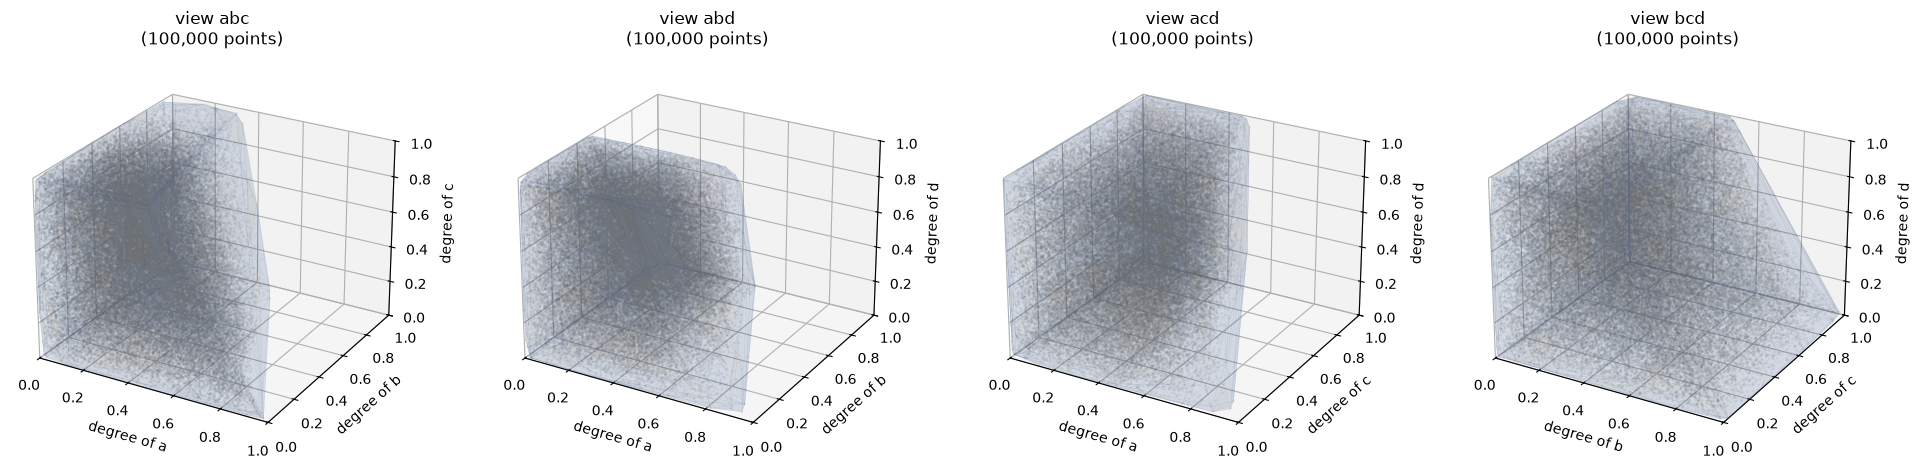

In [21]:
triples = list(combinations(range(4), 3))
fig = plt.figure(figsize=(24, 6))

# one 3D plot per triple, with all 100,000 points
for k, idx in enumerate(triples):
    names = [arguments_4[i] for i in idx]
    Y = X[:, idx]  # keep only the 3 chosen arguments
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    ax.scatter(Y[:, 0], Y[:, 1], Y[:, 2], s=1, color="grey", alpha=0.3)
    draw_hull_3d(ax, Y, compute_hull(Y), names)
    ax.set_title(f"view {''.join(names)}\n(100,000 points)")
    ax.view_init(25, -60)

plt.show()

- We get 4 plots because we can only show 3 arguments at a time, so each view leaves one argument out (abc hides d, abd hides c, acd hides b, bcd hides a).
- Each view looks like one of the 3-argument graphs we already know:
  - **abc**: a is attacked by b and c, like the two attackers. a can only be strong when b and c are both weak.
  - **abd**: d → b → a, like the chain.
  - **acd** and **bcd**: only one attack is visible (c → a, d → b), so only one side of the cube is cut. In **bcd**, the corner where b and d are both strong is missing, and c is free.
- So the 4D space is built from the same cuts as before: one ceiling per attacked argument.
- But each view hides part of the story: a is attacked twice, and if we don't see one of its attackers, we can't understand why it is so low. In **acd**, a is sometimes low even when c is weak: the reason is b, which is hidden in this view.
- So the 3D views show the shape of the space, but they are hard to interpret alone. Let's see what the heat-map adds.

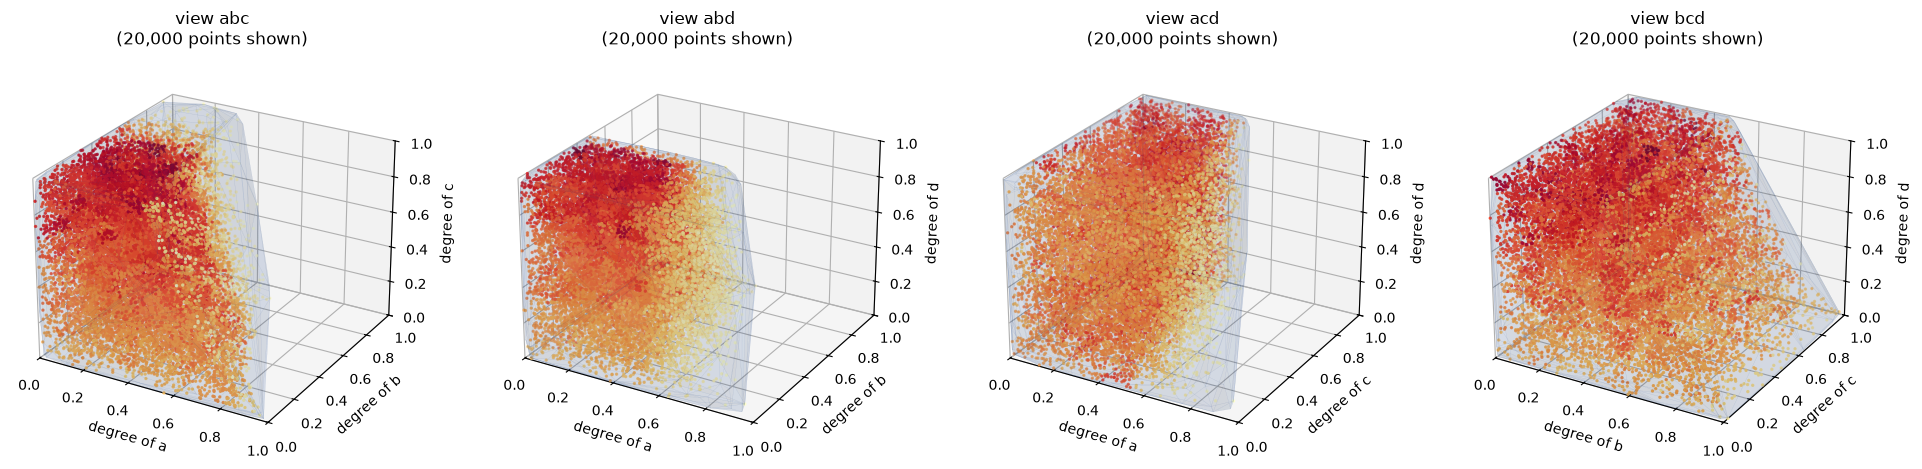

In [22]:
fig = plt.figure(figsize=(24, 6))

for k, idx in enumerate(triples):
    names = [arguments_4[i] for i in idx]
    Y = X[:, idx]
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    draw_heatmap_3d(ax, Y, n_show=20_000)
    draw_hull_3d(ax, Y, compute_hull(Y), names)
    ax.set_title(f"view {''.join(names)}\n(20,000 points shown)")
    ax.view_init(25, -60)
plt.show()

- Like with 2 and 3 arguments, the points pile up where an attacked argument is squeezed.
- The darkest part is where a is low, since a has two attackers and b only one, a is squeezed more often.
- a can almost reach 1, but it rarely does: it needs b and c to be weak at the same time.

But these views have one main limit: when a is low, we cannot always tell who is responsible. a has two attackers, and in some views one of them is missing. 

The second idea answers this: we keep a and b on a 2D plot and use the colour to show the argument we cannot see.

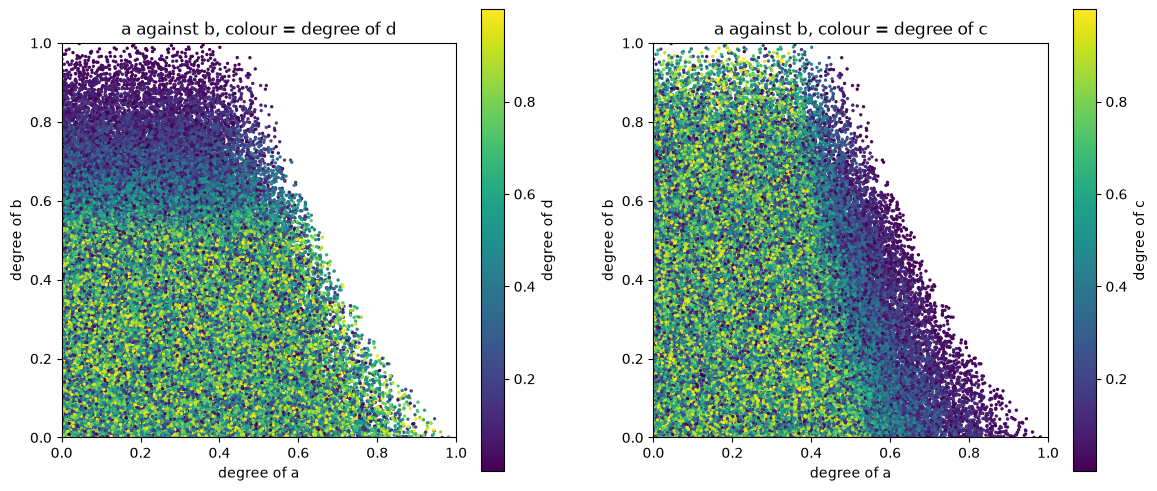

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# a against b, coloured by d (left) and by c (right)
n_show = 100_000
for ax, col, name in [(axes[0], 3, "d"), (axes[1], 2, "c")]:
    points = ax.scatter(X[:n_show, 0], X[:n_show, 1], c=X[:n_show, col], cmap="viridis", s=2)
    fig.colorbar(points, ax=ax, label=f"degree of {name}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("degree of a"); ax.set_ylabel("degree of b")
    ax.set_title(f"a against b, colour = degree of {name}")

plt.show()

- **Using Color For C**: c is strong only when a is below about 0.5, whatever the degree of b. So when c is strong, it caps a: a can only be strong if c is weak. When a is low and the point is yellow, c is responsible.
- **Using Color For D**: d is strong for every degree of a, but it becomes weak when b gets high. So d does not limit a directly, it limits b: b can only be strong if d is weak. This matches the graph: d attacks b, not a, and only acts on a through b.

What this solves :
compared to the 3D views: we can now see which argument is responsible when another one is low, and whether its effect is direct (c on a) or goes through another argument (d on a, through b).

What it introduces:
we only see one extra argument at a time, and the points overlap, so we only see the colour of the points drawn last.

To compare with 2 and 3 arguments, we compute the same three metrics. The hull can still be computed in 4D, even if we cannot draw it.

In [24]:
row = {"hull volume (4D)": compute_hull(X).volume}
for i, a in enumerate(arguments_4):
    row[f"mean Deg({a})"] = X[:, i].mean()
row["all > 0.5 (%)"] = 100 * np.mean((X > 0.5).all(axis=1))
pd.DataFrame([row], index=["d -> b -> a, c -> a"]).round(3)

,hull volume (4D),mean Deg(a),mean Deg(b),mean Deg(c),mean Deg(d),all > 0.5 (%)
"d -> b -> a, c -> a",0.46,0.282,0.346,0.5,0.5,0.0


Based on the metrics we calculated:

- **Size**: 0.46. The space keeps getting smaller as we add attacks (0.75 for b → a, 0.59 for two attackers).
- **What is impossible**: the four degrees are never above 0.5 together (0%, against 6.25% without attacks): a needs b and c to be weak at the same time.
- **Where the points fall**: b has one attacker (0.35), a has two (0.28). a is a bit higher than with two free attackers (0.26) because d weakens b.

Is the heat-map still stable? Same test, with 6 x 6 x 6 x 6 = 1,296 cells (close to 2D and 3D).

In [25]:
grids = []
for seed in range(6):
    W, X = degrees_for_random_weights(arguments_4, attacks_4, seed=seed)
    grids.append(density_grid(X, bins=6))

diffs = []
for i in range(6):
    for j in range(i + 1, 6):
        diffs.append(heatmap_difference(grids[i], grids[j]))

pd.DataFrame([{"mean difference": np.mean(diffs), "min": np.min(diffs), "max": np.max(diffs)}],
             index=["d -> b -> a, c -> a"]).round(4)

,mean difference,min,max
"d -> b -> a, c -> a",0.0439,0.0416,0.0456


- About 4.4% difference between two draws, like with 2 and 3 arguments: 100,000 samples are still enough.

### What still stands?

1. Do the attacks cut the region where all arguments are strong? -> yes (volume 0.46, all > 0.5 = 0%).
2. Do the points pile up where an argument is squeezed? -> yes, around a.
3. Do the defence and the attacks add up? -> yes, a ends up between two attackers (0.26) and one attacker (0.35).
4. Is the heat-map stable? -> yes (4.4%).

### What is new with 4 arguments?

- Nothing new about the space itself: it behaves like with 2 and 3 arguments.
- What changes is how we can see it: we cannot draw it anymore, and each 3D view hides part of it. We need 3D views, colour and numbers together, and only the numbers can measure it.

### More arguments

With 4 arguments we already needed several views, colours and numbers to understand the space. Does our method still work with more arguments?

We're going to try it on chains $x_n \to \dots \to x_2 \to x_1$.

In [26]:
rows = []
for n in range(2, 8):  # n = 7 takes about 2-3 minutes
    # chain x_n -> ... -> x_1
    names = [f"x{i}" for i in range(1, n + 1)]
    chain = [(names[i + 1], names[i]) for i in range(n - 1)]
    W, X = degrees_for_random_weights(names, chain, seed=0)
    # time to compute the hull
    start = time.time()
    hull = compute_hull(X)
    rows.append({"n": n,
                 "3D views": comb(n, 3),
                 "hull faces": len(hull.simplices),
                 "hull time (s)": time.time() - start})
pd.DataFrame(rows).round(2).set_index("n")

,3D views,hull faces,hull time (s)
n,,,
2,0,24,0.02
3,1,246,0.03
4,4,2957,0.07
5,10,31196,0.55
6,20,303275,8.90
7,35,3241852,250.91


- The number of 3D views explodes: 20 for 6 arguments, and it would be 56 for 8, 120 for 10. It's not easy to read them and interperate them.
- The hull gets about 10 times more faces with each new argument, and the time grows the same way.

So the method asked in the statement (hull + heat-map) stops working here. To still say something about the space, we're **going beyond the visualisation** and propose two ways to describe it with numbers. These are our own proposals, not part of the statement:
1. **Proposal 1**: measure how big the space is, without the hull.
2. **Proposal 2**: find where the space is cut, with one matrix for all the pairs of arguments.

#### Proposal 1: how big is the space, without the hull?

The hull does not work anymore, so we try another way to measure the space. Our idea is to test points directly. We go backwards: instead of going from weights to degrees, we pick random degrees and compute the weights they would need. This is the formula of Question 1 turned around:

$$w(a) = Deg(a) \times (1 + \text{sum of the degrees of the attackers of } a)$$

If all these weights are $\leq 1$, the point can be reached, so it is in the space. If one weight is above 1, no weighted graph can give this point. The share of accepted points is the volume of the space (`real_space_volume`).

We check it first on b attacks a, where we know the answer.

In [30]:
arguments_2 = ["a", "b"]
b_attacks_a = TWO_ARGUMENT_GRAPHS["b attacks a"]
W, X = degrees_for_random_weights(arguments_2, b_attacks_a, seed=0)

print("hull area:        ", round(compute_hull(X).volume, 3))
print("real space volume:", round(real_space_volume(arguments_2, b_attacks_a), 3))

hull area:         0.748
real space volume: 0.693


- The real volume is a bit smaller than the hull. This is the white space we saw between the points and the hull edge. So this method measures the space itself, not its hull.

Now we can use it on chains that are too long for the hull.

In [31]:
rows = []
for n in [2, 3, 4, 6, 8, 10, 15]:
    names = [f"x{i}" for i in range(1, n + 1)]
    chain = [(names[i + 1], names[i]) for i in range(n - 1)]
    rows.append({"n": n, "real space volume": real_space_volume(names, chain)})
pd.DataFrame(rows).round(3).set_index("n")

,real space volume
n,
2,0.693
3,0.524
4,0.389
6,0.216
8,0.120
10,0.066
15,0.015


- The space keeps getting smaller: each new attack cuts it again.
- It takes less than a second for any n.

So far the volume tells us how big the space is, but not where it is cut.

#### Proposal 2: where is the space cut?

With 2 arguments, an attack cuts the corner where both are strong, so the cloud of points leans down: when one degree goes up, the other goes down. We can measure this with one number for each pair of arguments, the **correlation**:
- negative: the space is cut like an attack;
- positive: they go up together, like a defence;
- around 0: the space is not cut between them.

We put all the pairs in one matrix and colour it (red = attack, blue = defence, white = nothing). This is not the same heat-map as before: the colour is not the number of points anymore, it is the link between two arguments.

We check it first on our 4-argument graph, where we already know the answer.

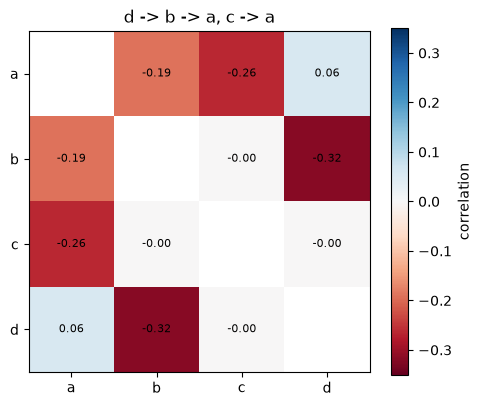

In [32]:
W, X = degrees_for_random_weights(arguments_4, attacks_4, seed=0)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = draw_correlation_matrix(ax, X, arguments_4)
fig.colorbar(image, ax=ax, label="correlation")
ax.set_title("d -> b -> a, c -> a")
plt.show()

- Red for b–a, c–a and d–b: the three attacks.
- Light blue for d–a: d defends a.
- White for c–d and b–c: no link.

The matrix finds what we saw with the 3D views and the colours. Now we use it on a chain of 8 arguments, which we cannot draw.

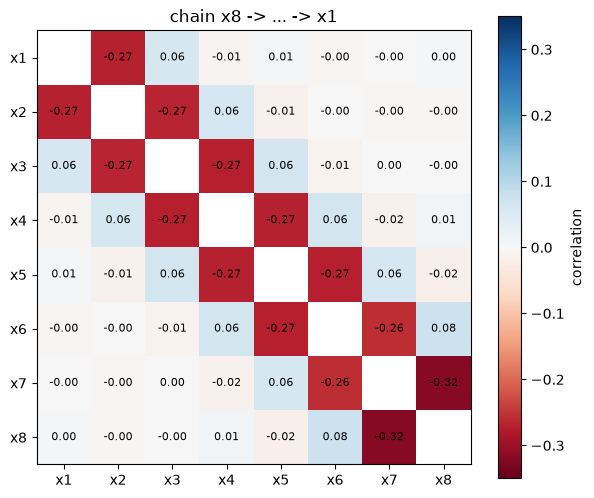

In [34]:
names_8 = [f"x{i}" for i in range(1, 9)]
chain_8 = [(names_8[i + 1], names_8[i]) for i in range(7)]  # x8 -> x7 -> ... -> x1
W, X = degrees_for_random_weights(names_8, chain_8, seed=0)

fig, ax = plt.subplots(figsize=(7, 6))
image = draw_correlation_matrix(ax, X, names_8)
fig.colorbar(image, ax=ax, label="correlation")
ax.set_title("chain x8 -> ... -> x1")
plt.show()

- A red band next to the diagonal: each argument is attacked by its neighbour.
- A light blue band just after: the attacker of my attacker defends me.
- White everywhere else: after 2 steps, an argument has almost no influence.

### What still stands?

1. Do the attacks cut the space? -> yes, the volume keeps going down, and every attack shows up in red.
2. Does the defence still help? -> yes, in blue, but it is weaker than the attack and fades after 2 steps.

### What is new with more arguments?

- The method of the statement (hull + heat-map) stops working: we cannot draw the space or build its hull anymore.
- Our two proposals go beyond the visualisation: we do not look at the space anymore, we describe it with numbers. We can still measure how big it is (real volume) and where it is cut (correlation matrix), for any number of arguments, but we lose its exact shape.

## Step 8: Our analysis

**What the space tells us about the weighted h-categorizer**
- The hull shows which degrees are **possible**, the heat-map shows which ones are **frequent**.
- The shape of the space is decided by the graph: every attack cuts away the region where the arguments are strong together. The weights only choose a point inside this space.
- An unattacked argument keeps its weight and covers its whole axis; an attack weakens; two attacks add up; an argument can be defended by the attacker of its attacker.
- The heat-map is not uniform: the points pile up where an argument is squeezed.

**What we learned about the method**
- The heat-map is resilient to re-sampling: with 100,000 samples, two draws differ by only about 5–6%, for every graph and up to 4 arguments.
- The hull is a good approximation only when the border of the space is straight: when it is curved, it covers empty areas (0.748 against 0.693 for b attacks a).
- Up to 3 arguments we can see the whole space. With 4, we need 3D views, colours and numbers. Beyond, the hull cannot be computed anymore (2 min for 7 arguments, out of memory for 8), so we proposed to describe the space with numbers: its real volume and a correlation matrix.